# Survival model: is LightGBM the right model family?

`MODELS.md` benchmarks the competing-risks survival model against a hazard table by loan age. That is a
naive lookup, not a model, so beating it shows only that the features carry information. This notebook asks the
fairer question: **on the same loan-months, the same features and the same out-of-time split, how does
LightGBM compare with the standard parametric alternative, a multinomial logistic discrete-time hazard?**

| # | Model | What it can learn |
|---|---|---|
| 1 | Hazard table by loan age | Age only (the benchmark already in `MODELS.md`) |
| 2 | Multinomial logistic hazard | The same 23 features, additive on the log-odds scale, smooth age curve |
| 3 | LightGBM (shipped) | The same 23 features, interactions and non-linearities |

Protocol, copied from `backend/export_survival_model.py` (validation fit): fit on loan-months before 2023-01
using loan buckets 3-9, with bucket 2 for early stopping; judge on every loan-month from 2023-01. The last month
of each data release is left out. Nothing here writes to `src/main/resources`.

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
os.chdir("../backend")                      # credit_common uses paths relative to backend/
sys.path.insert(0, os.getcwd())

import numpy as np, polars as pl, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

import export_survival_model as esm         # reuse the production featurisation and LightGBM fit
from credit_common import CATEGORICAL, MODEL_NUMERIC, MACRO_FEATURES, SURVIVAL, category_mappings, loan_bucket

## Data, built exactly as in the production script

In [2]:
mappings = category_mappings()
loans = pl.read_parquet(str(SURVIVAL / "loans" / "*.parquet"))
finals = esm.release_final_months(loans)
rows = pl.read_parquet(str(SURVIVAL / "rows" / "*.parquet")).filter(~pl.col("month").is_in(finals))
rows = esm.featurize(rows, pl.col("month") - pl.col("loan_age").cast(pl.Int32), mappings).with_columns(
    bucket=loan_bucket(pl.col("loan_sequence_number"))).sort(["loan_sequence_number", "loan_age"])

past = rows.filter(pl.col("month") < esm.TEST_START)
test = rows.filter(pl.col("month") >= esm.TEST_START)
train = past.filter(pl.col("bucket") >= 3)
valid = past.filter(pl.col("bucket") == 2)
y, w = test["label"].to_numpy(), test["weight"].to_numpy()
print(f"train {train.height:,}   valid {valid.height:,}   out-of-time test {test.height:,}")
print("features:", len(esm.FEATURES), esm.FEATURES)

train 1,896,759   valid 272,125   out-of-time test 2,429,834
features: 23 ['credit_score', 'original_dti', 'original_upb', 'original_cltv', 'original_ltv', 'rate_spread', 'original_loan_term', 'number_of_borrowers', 'number_of_units', 'mi_percent', 'occupancy_status', 'property_type', 'loan_purpose', 'channel', 'first_time_homebuyer_flag', 'property_state', 'loan_age', 'regime_stressed', 'rate_incentive', 'unemployment', 'unemployment_change_12m', 'hpi_change_12m', 'mtm_ltv']


## 1. Hazard table by loan age (the existing benchmark)

In [3]:
cols = [(pl.col("weight") * (pl.col("label") == k)).sum().alias(f"c{k}") for k in range(3)]
table = train.group_by("loan_age").agg(cols).with_columns(total=pl.col("c0") + pl.col("c1") + pl.col("c2"))
overall = train.select(cols).to_numpy()[0]; overall = overall / overall.sum()
lookup = {int(a): np.array([c0, c1, c2]) / t for a, c0, c1, c2, t in table.iter_rows()}
p_age = np.array([lookup.get(int(a), overall) for a in test["loan_age"].to_list()])

## 2. Multinomial logistic hazard

Built to be a *fair* opponent, not a straw man:

- every numeric feature standardised, missing values median-filled;
- **loan age enters through a cubic spline**, because the hazard is not linear in age and a linear term would
  handicap the logistic model for no good reason;
- categoricals one-hot encoded (state included);
- the same sample weights (the 10% no-event subsample carries weight 10) and the same train split.

In [4]:
num = [c for c in esm.FEATURES if c not in CATEGORICAL and c != "loan_age"]
pre = ColumnTransformer([
    ("age", SplineTransformer(n_knots=8, degree=3, extrapolation="constant"), ["loan_age"]),
    ("num", make_pipeline(__import__("sklearn.impute", fromlist=["SimpleImputer"]).SimpleImputer(strategy="median"),
                          StandardScaler()), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=200), CATEGORICAL),
])
logit = make_pipeline(pre, LogisticRegression(max_iter=300, C=1.0))

def frame(df):
    return df.select(esm.FEATURES).to_pandas()

t0 = time.time()
logit.fit(frame(train), train["label"].to_numpy(), logisticregression__sample_weight=train["weight"].to_numpy())
p_logit = logit.predict_proba(frame(test))
print(f"logistic hazard fitted in {time.time() - t0:.0f}s")

logistic hazard fitted in 60s


## 3. LightGBM (the shipped model, same parameters and early stopping as production)

In [5]:
t0 = time.time()
booster, best_iteration = esm.fit(train, valid)
p_lgbm = booster.predict(esm.matrix(test))
print(f"LightGBM fitted in {time.time() - t0:.0f}s, best iteration {best_iteration}")

[100]	valid_0's multi_logloss: 0.0808511


[200]	valid_0's multi_logloss: 0.0807205


[300]	valid_0's multi_logloss: 0.0806945


[400]	valid_0's multi_logloss: 0.0806888


[500]	valid_0's multi_logloss: 0.0806863


LightGBM fitted in 116s, best iteration 472


## Results

In [6]:
def norm(p):
    return p / p.sum(axis=1, keepdims=True)

def score(name, p):
    out = {"model": name, "weighted log loss": log_loss(y, norm(p), sample_weight=w, labels=[0, 1, 2]),
           "default AUC": roc_auc_score(y == 1, p[:, 1], sample_weight=w) if name != "Hazard table (age only)" else np.nan,
           "prepay AUC": roc_auc_score(y == 2, p[:, 2], sample_weight=w) if name != "Hazard table (age only)" else np.nan}
    for cause, k in (("default", 1), ("prepay", 2)):
        out[f"{cause} actual/predicted"] = np.average(y == k, weights=w) / np.average(p[:, k], weights=w)
    return out

results = pd.DataFrame([score("Hazard table (age only)", p_age),
                        score("Multinomial logistic hazard", p_logit),
                        score("LightGBM (shipped)", p_lgbm)]).set_index("model")
base = results.loc["Hazard table (age only)", "weighted log loss"]
results["log loss vs age table"] = (results["weighted log loss"] / base - 1).map("{:+.1%}".format)
results.round(4)

,weighted log loss,default AUC,prepay AUC,default actual/predicted,prepay actual/predicted,log loss vs age table
model,,,,,,
Hazard table (age only),0.0467,NaN,NaN,0.4603,0.2712,+0.0%
Multinomial logistic hazard,0.0375,0.7577,0.6006,1.0365,0.8434,-19.7%
LightGBM (shipped),0.0360,0.7905,0.6618,1.3489,0.9880,-22.9%


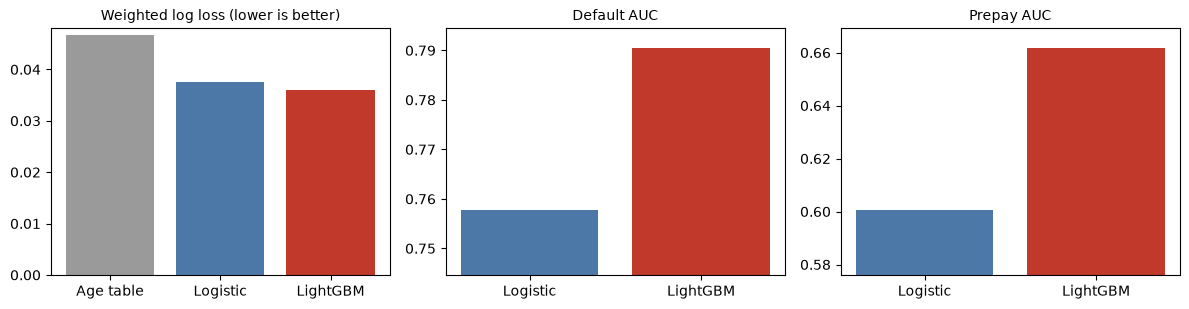

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
names = ["Age table", "Logistic", "LightGBM"]
for a, col, title in zip(ax, ["weighted log loss", "default AUC", "prepay AUC"], ["Weighted log loss (lower is better)", "Default AUC", "Prepay AUC"]):
    a.bar(names, results[col].values, color=["#9a9a9a", "#4c78a8", "#c0392b"]); a.set_title(title, fontsize=10)
    lo = np.nanmin(results[col].values); hi = np.nanmax(results[col].values); pad = (hi - lo) * 0.4 or 0.01
    a.set_ylim(lo - pad if col != "weighted log loss" else 0, hi + pad * 0.3)
plt.tight_layout(); plt.show()

### Calibration by risk decile (default hazard, out of time)

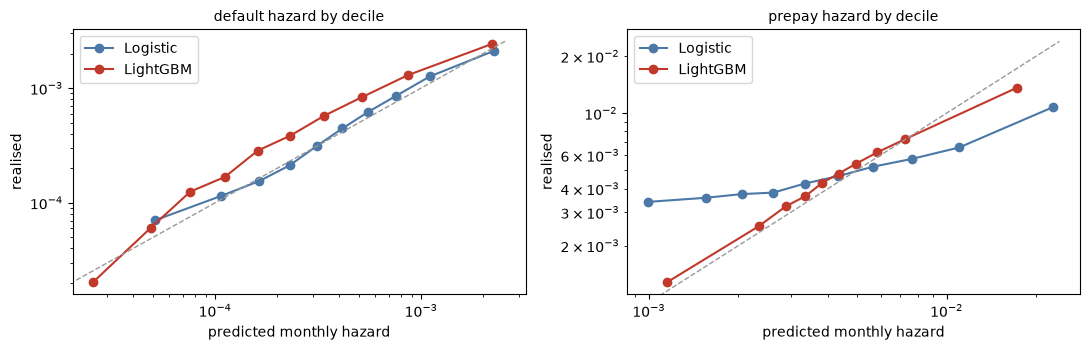

In [8]:
def deciles(p, k):
    d = pd.DataFrame({"p": p[:, k], "e": (y == k).astype(float), "w": w})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), 10, labels=False)
    g = d.groupby("bin").apply(lambda x: pd.Series({"predicted": np.average(x.p, weights=x.w), "actual": np.average(x.e, weights=x.w)}))
    return g

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (cause, k) in zip(ax, (("default", 1), ("prepay", 2))):
    for name, p, c in (("Logistic", p_logit, "#4c78a8"), ("LightGBM", p_lgbm, "#c0392b")):
        g = deciles(p, k); a.plot(g.predicted, g.actual, "o-", label=name, color=c)
    m = max(a.get_xlim()[1], a.get_ylim()[1]); a.plot([0, m], [0, m], "--", color="#999", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("predicted monthly hazard"); a.set_ylabel("realised"); a.set_title(f"{cause} hazard by decile", fontsize=10); a.legend()
plt.tight_layout(); plt.show()

### What the extra flexibility buys: the largest gap between the two models, by risk of default

In [9]:
d = pd.DataFrame({"y": (y == 1).astype(float), "w": w, "logit": p_logit[:, 1], "lgbm": p_lgbm[:, 1]})
d["top"] = pd.qcut(d.lgbm.rank(method="first"), 100, labels=False) >= 99     # LightGBM's riskiest 1% of loan-months
rows_ = []
for label, m in (("all loan-months", np.ones(len(d), bool)), ("riskiest 1% by LightGBM", d.top.values)):
    s = d[m]
    rows_.append({"segment": label, "realised": np.average(s.y, weights=s.w),
                  "logistic predicted": np.average(s.logit, weights=s.w), "LightGBM predicted": np.average(s.lgbm, weights=s.w)})
pd.DataFrame(rows_).set_index("segment").round(5)

,realised,logistic predicted,LightGBM predicted
segment,,,
all loan-months,0.00061,0.00059,0.00045
riskiest 1% by LightGBM,0.00381,0.00261,0.00537


## Reading the results

Numbers from the run above (out of time, 2,429,834 loan-months from 2023-01; the LightGBM row reproduces the
figures in `MODELS.md`: log loss 0.0360, default AUC 0.7905, prepay AUC 0.6618).

- **LightGBM beats a well-built logistic hazard on every ranking metric.** Log loss 0.0360 vs 0.0375, default
  AUC 0.791 vs 0.758, prepay AUC 0.662 vs 0.601. The flexible model family earns its place, mostly on
  prepayment, where the drivers interact (rate incentive, age, balance).
- **Most of the gain over the age table comes from the features, not the algorithm.** The logistic model already
  closes about 86% of the log-loss gap that LightGBM closes (0.0467 to 0.0375 against 0.0467 to 0.0360). The
  claim "the model beats a hazard table" in `MODELS.md` is true, but it is the weaker half of the story.
- **Calibration is not a clean win for LightGBM.** Before the production drift overlay, realised default
  over predicted is 1.35 for LightGBM and 1.04 for the logistic model. LightGBM under-predicts default across
  2023 onwards, which is the drift the overlay (x1.05 in production) exists to correct. The logistic model's
  smoother extrapolation into unseen macro levels happens to sit closer on the aggregate. In the riskiest 1% of
  loan-months LightGBM over-predicts (0.0054 vs 0.0038 realised) and the logistic model under-predicts (0.0026),
  matching the 0.82 over-prediction of the top percentile noted in `MODELS.md`.
- **Prepayment** is under-predicted by both (actual/predicted 0.99 LightGBM, 0.84 logistic), so LightGBM is
  the better calibrated of the two there.

### Limits of this comparison

- One split and one run: no confidence intervals or repeated fits, so small log-loss gaps should not be over-read.
  The AUC gaps (0.03 default, 0.06 prepay) are large relative to that.
- The logistic model uses the default regularisation (C = 1) and 300 iterations, and warnings are suppressed in
  this notebook, so convergence was not verified. It has no interaction terms; adding some would narrow the gap.
- Not tested: a Cox model (needs a counting-process layout for time-varying covariates), XGBoost/CatBoost
  (expected to match LightGBM), or a neural survival model.
- The production drift overlay and the final all-months refit are out of scope here: this is the validation fit only.
